In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns


In [4]:
df=pd.read_csv("Credit Card Fraud Risk Analysis.csv")
print(df.head())

   Transaction ID  Customer Name Merchant Name Transaction Date  \
0        17797619     Pihu Manne          Uber       2024-11-10   
1        50040671   Hiran Vaidya        Zomato       2024-05-20   
2        88177651     Shalv Vasa        Myntra       2024-05-28   
3        24228305  Taran Shanker     Lifestyle       2024-01-09   
4        87307869   Shanaya Kara     Tata Cliq       2024-07-27   

   Transaction Amount (INR) Fraud Risk        Fraud Type          State  \
0                     11673     Medium  Card Not Present      Telangana   
1                     16594     Medium          Phishing    Maharashtra   
2                     23347     Medium     Card Skimming  Uttar Pradesh   
3                     20753        Low     Card Skimming         Kerala   
4                      6432        Low     Card Skimming          Delhi   

  Card Type          Bank  IsFraud  Fraud Score Transaction Category  \
0     Rupay    ICICI Bank        0           57       Transportation   
1 

In [5]:
df.shape

(1000, 14)

In [6]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 14 columns):
 #   Column                    Non-Null Count  Dtype 
---  ------                    --------------  ----- 
 0   Transaction ID            1000 non-null   int64 
 1   Customer Name             1000 non-null   object
 2   Merchant Name             1000 non-null   object
 3   Transaction Date          1000 non-null   object
 4   Transaction Amount (INR)  1000 non-null   int64 
 5   Fraud Risk                1000 non-null   object
 6   Fraud Type                1000 non-null   object
 7   State                     1000 non-null   object
 8   Card Type                 1000 non-null   object
 9   Bank                      1000 non-null   object
 10  IsFraud                   1000 non-null   int64 
 11  Fraud Score               1000 non-null   int64 
 12  Transaction Category      1000 non-null   object
 13  Merchant Location         1000 non-null   object
dtypes: int64(4), object(10)
m

In [7]:
df.columns

Index(['Transaction ID', 'Customer Name', 'Merchant Name', 'Transaction Date',
       'Transaction Amount (INR)', 'Fraud Risk', 'Fraud Type', 'State',
       'Card Type', 'Bank', 'IsFraud', 'Fraud Score', 'Transaction Category',
       'Merchant Location'],
      dtype='object')

In [8]:
df.columns.tolist()

['Transaction ID',
 'Customer Name',
 'Merchant Name',
 'Transaction Date',
 'Transaction Amount (INR)',
 'Fraud Risk',
 'Fraud Type',
 'State',
 'Card Type',
 'Bank',
 'IsFraud',
 'Fraud Score',
 'Transaction Category',
 'Merchant Location']

In [9]:
df.describe()

,Transaction ID,Transaction Amount (INR),IsFraud,Fraud Score
count,1.000000e+03,1000.000000,1000.000000,1000.000000
mean,5.486023e+07,12226.843000,0.286000,53.179000
std,2.616482e+07,7106.084734,0.452115,25.723815
min,1.003645e+07,141.000000,0.000000,10.000000
25%,3.235345e+07,6218.000000,0.000000,29.000000
50%,5.379576e+07,11999.500000,0.000000,54.000000
75%,7.790521e+07,18207.750000,1.000000,76.000000
max,9.994398e+07,24993.000000,1.000000,95.000000


In [10]:
df.isnull().sum()

Transaction ID              0
Customer Name               0
Merchant Name               0
Transaction Date            0
Transaction Amount (INR)    0
Fraud Risk                  0
Fraud Type                  0
State                       0
Card Type                   0
Bank                        0
IsFraud                     0
Fraud Score                 0
Transaction Category        0
Merchant Location           0
dtype: int64

In [19]:
df.duplicated().sum()

0

In [21]:
df['Transaction ID'].duplicated().sum()

0

In [23]:
df['IsFraud'].value_counts()

IsFraud
0    714
1    286
Name: count, dtype: int64

In [25]:
df['IsFraud'].value_counts(normalize=True)*100

IsFraud
0    71.4
1    28.6
Name: proportion, dtype: float64

In [27]:
fraud_count=df['IsFraud'].value_counts()
print("Legimate Transactions: ", fraud_count.get(0,0))
print("Fraud Transactions: ", fraud_count.get(1,0))

fraud_rate=df['IsFraud'].mean()*100
print(f"Fraud Rate : {fraud_rate:.2f}%")

Legimate Transactions:  714
Fraud Transactions:  286
Fraud Rate : 28.60%


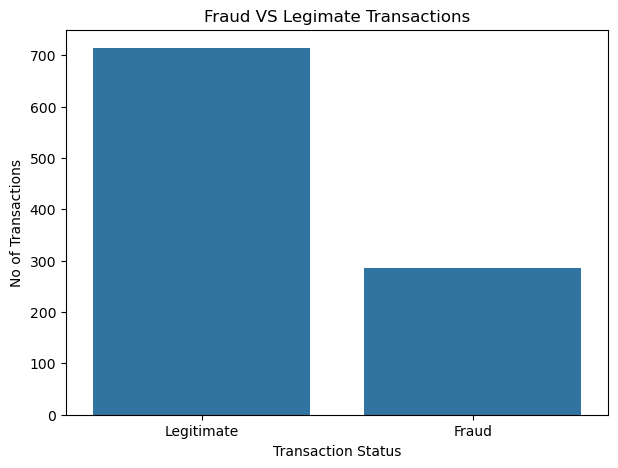

In [30]:


plt.figure(figsize=(7,5))
sns.countplot(data=df,x='IsFraud')
plt.title('Fraud VS Legimate Transactions')
plt.xlabel('Transaction Status')
plt.ylabel('No of Transactions')
plt.xticks([0, 1], ['Legitimate', 'Fraud'])
plt.show()

In [32]:
df['Fraud Risk'].value_counts()

Fraud Risk
Low         400
Medium      297
High        196
Critical    107
Name: count, dtype: int64

In [34]:
pd.crosstab(df['Fraud Risk'], df['IsFraud'])

IsFraud,0,1
Fraud Risk,,
Critical,79,28
High,134,62
Low,287,113
Medium,214,83


In [36]:
fraud_risk_rate=(pd.crosstab(df['Fraud Risk'],df['IsFraud'],normalize='index')*100).round(2)
fraud_risk_rate

IsFraud,0,1
Fraud Risk,,
Critical,73.83,26.17
High,68.37,31.63
Low,71.75,28.25
Medium,72.05,27.95


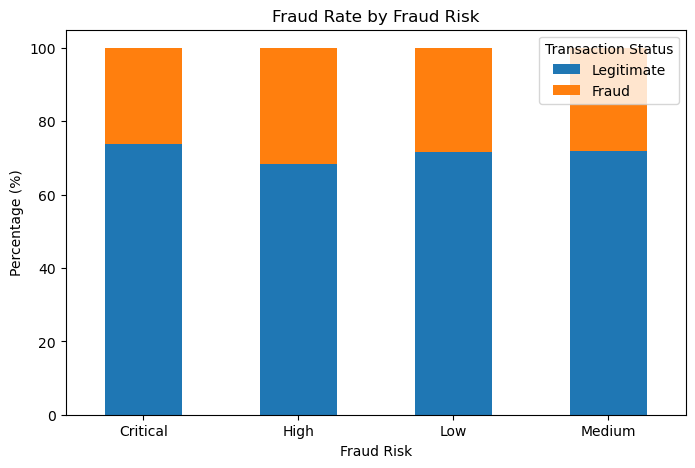

In [38]:
fraud_risk_rate.plot(
    kind='bar',
    stacked=True,
    figsize=(8,5)
)

plt.title('Fraud Rate by Fraud Risk')
plt.xlabel('Fraud Risk')
plt.ylabel('Percentage (%)')
plt.legend(
    title='Transaction Status',
    labels=['Legitimate', 'Fraud']
)
plt.xticks(rotation=0)
plt.show()

In [40]:
df['Fraud Type'].value_counts()

Fraud Type
Card Not Present    231
Card Skimming       209
Identity Theft      195
Account Takeover    188
Phishing            177
Name: count, dtype: int64

In [42]:
pd.crosstab(df['Fraud Type'],df['IsFraud'])

IsFraud,0,1
Fraud Type,,
Account Takeover,142,46
Card Not Present,159,72
Card Skimming,155,54
Identity Theft,131,64
Phishing,127,50


In [44]:
fraud_type_rate=(pd.crosstab(df['Fraud Type'],df['IsFraud'],normalize='index')*100).round(2)
fraud_type_rate

IsFraud,0,1
Fraud Type,,
Account Takeover,75.53,24.47
Card Not Present,68.83,31.17
Card Skimming,74.16,25.84
Identity Theft,67.18,32.82
Phishing,71.75,28.25


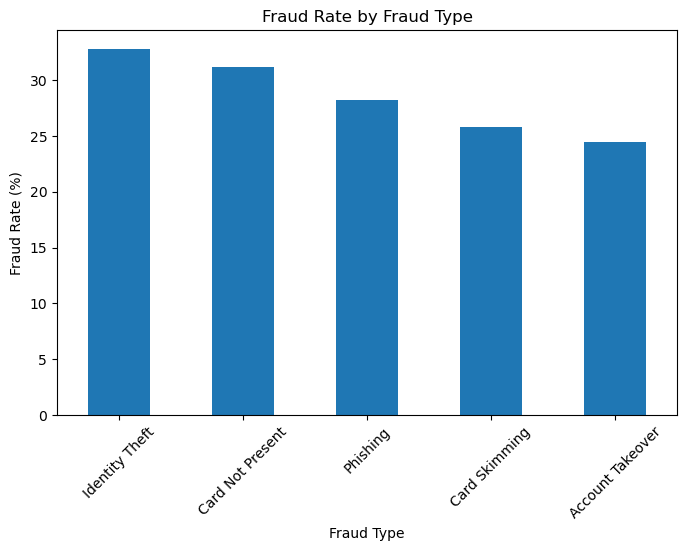

In [46]:



fraud_type_rate[1].sort_values(ascending=False).plot(
    kind='bar',
    figsize=(8,5)
)

plt.title('Fraud Rate by Fraud Type')
plt.xlabel('Fraud Type')
plt.ylabel('Fraud Rate (%)')
plt.xticks(rotation=45)
plt.show()

In [48]:
df.groupby('IsFraud')['Transaction Amount (INR)'].agg(['count','mean','median','min','max']).round(2)

,count,mean,median,min,max
IsFraud,,,,,
0,714,12493.04,12185.0,141,24993
1,286,11562.28,11552.0,179,24940


In [50]:
df.columns

Index(['Transaction ID', 'Customer Name', 'Merchant Name', 'Transaction Date',
       'Transaction Amount (INR)', 'Fraud Risk', 'Fraud Type', 'State',
       'Card Type', 'Bank', 'IsFraud', 'Fraud Score', 'Transaction Category',
       'Merchant Location'],
      dtype='object')

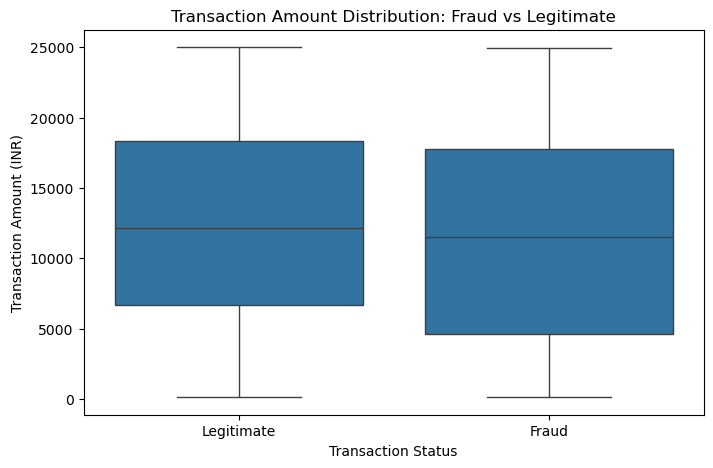

In [52]:
plt.figure(figsize=(8,5))

sns.boxplot(
    data=df,
    x='IsFraud',
    y='Transaction Amount (INR)'
)

plt.title('Transaction Amount Distribution: Fraud vs Legitimate')
plt.xlabel('Transaction Status')
plt.ylabel('Transaction Amount (INR)')
plt.xticks([0, 1], ['Legitimate', 'Fraud'])

plt.show()

In [54]:
df['Transaction Date'] = pd.to_datetime(df['Transaction Date'])
df['Transaction Date'].dtype

dtype('<M8[ns]')

In [56]:
df['Transaction Month']=df['Transaction Date'].dt.month
df['Transaction Day']=df['Transaction Date'].dt.day

In [58]:
fraud_by_month = (
    df.groupby('Transaction Month')['IsFraud']
    .agg(['count', 'sum'])
    .rename(columns={'sum': 'Fraud Count'})
)

fraud_by_month

,count,Fraud Count
Transaction Month,,
1,78,17
2,83,18
3,89,26
4,77,22
5,94,22
6,75,28
7,86,26
8,79,29
9,61,21


In [60]:
fraud_by_month['Fraud Rate(%)']=(fraud_by_month['Fraud Count']/fraud_by_month['count']*100).round(2)

fraud_by_month

,count,Fraud Count,Fraud Rate(%)
Transaction Month,,,
1,78,17,21.79
2,83,18,21.69
3,89,26,29.21
4,77,22,28.57
5,94,22,23.40
6,75,28,37.33
7,86,26,30.23
8,79,29,36.71
9,61,21,34.43


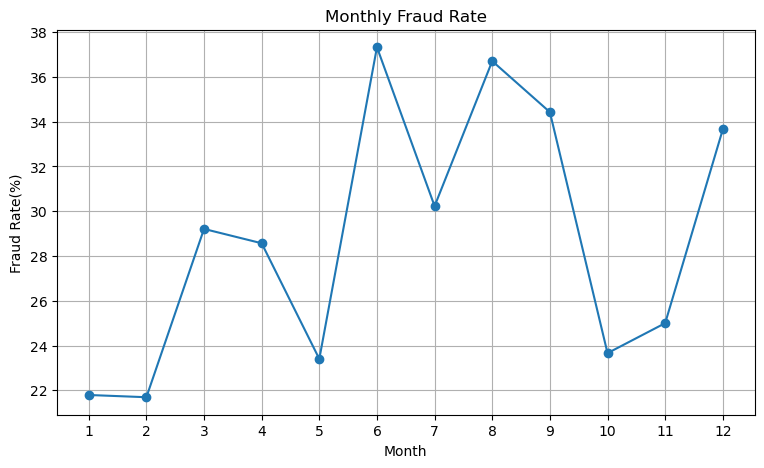

In [62]:
plt.figure(figsize=(9,5))

plt.plot(
    fraud_by_month.index,
    fraud_by_month['Fraud Rate(%)'],
    marker='o'
)

plt.title('Monthly Fraud Rate')
plt.xlabel('Month')
plt.ylabel('Fraud Rate(%)')
plt.xticks(range(1, 13))
plt.grid(True)

plt.show()

In [64]:
df.columns

Index(['Transaction ID', 'Customer Name', 'Merchant Name', 'Transaction Date',
       'Transaction Amount (INR)', 'Fraud Risk', 'Fraud Type', 'State',
       'Card Type', 'Bank', 'IsFraud', 'Fraud Score', 'Transaction Category',
       'Merchant Location', 'Transaction Month', 'Transaction Day'],
      dtype='object')

In [66]:
fraud_by_state=(pd.crosstab(df['State'],df['IsFraud'],normalize='index')*100).round(2)
fraud_by_state

IsFraud,0,1
State,,
Delhi,77.17,22.83
Gujarat,75.53,24.47
Karnataka,64.58,35.42
Kerala,77.66,22.34
Maharashtra,66.36,33.64
Rajasthan,69.91,30.09
Tamil Nadu,72.55,27.45
Telangana,72.45,27.55
Uttar Pradesh,71.00,29.00


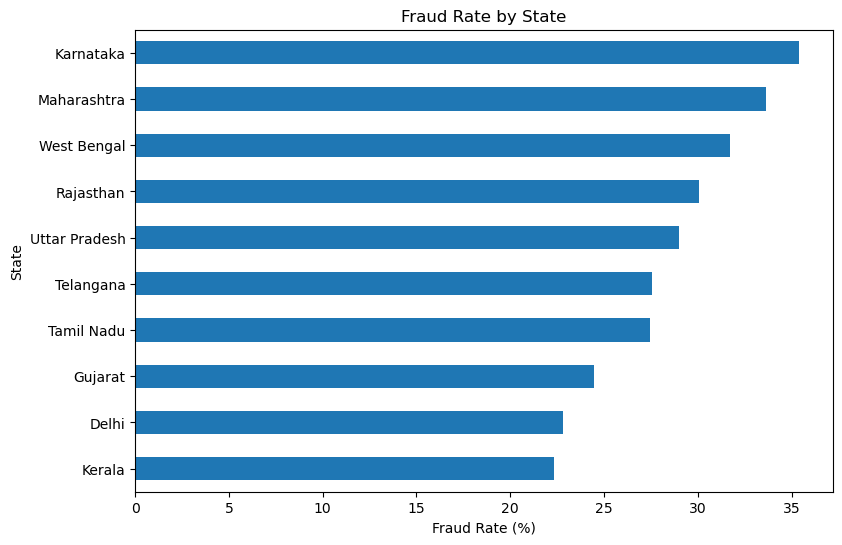

In [68]:

fraud_by_state[1].sort_values().plot(
    kind='barh',
    figsize=(9, 6)
)

plt.title('Fraud Rate by State')
plt.xlabel('Fraud Rate (%)')
plt.ylabel('State')
plt.show()

In [70]:
merchent_location_rate=(pd.crosstab(df['Merchant Location'],df['IsFraud'],normalize='index')*100).round(2)
merchent_location_rate

IsFraud,0,1
Merchant Location,,
Ahmedabad,63.27,36.73
Bangalore,73.55,26.45
Chennai,64.95,35.05
Delhi,81.11,18.89
Hyderabad,76.47,23.53
Jaipur,74.53,25.47
Kochi,66.29,33.71
Kolkata,78.79,21.21
Lucknow,70.00,30.00


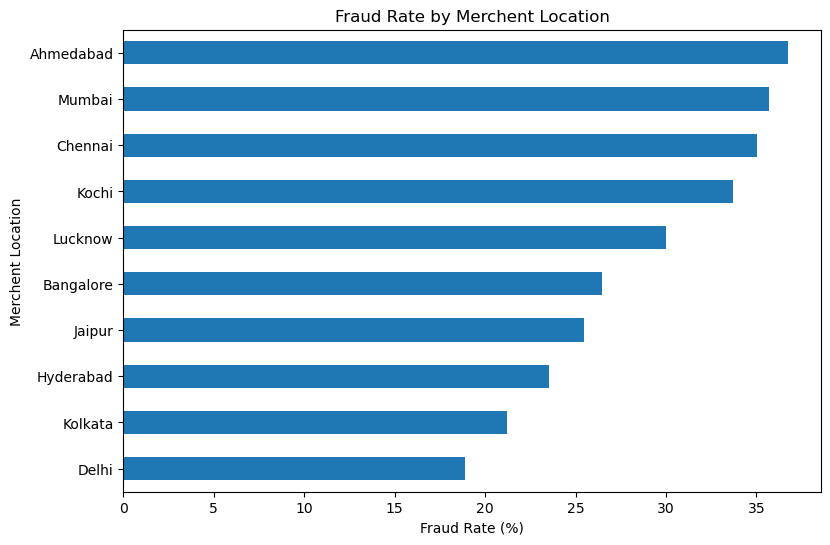

In [72]:

merchent_location_rate[1].sort_values().plot(
    kind='barh',
    figsize=(9, 6)
)

plt.title('Fraud Rate by Merchent Location')
plt.xlabel('Fraud Rate (%)')
plt.ylabel('Merchent Location')
plt.show()

In [74]:
card_type_rate=(pd.crosstab(df['Card Type'],df['IsFraud'],normalize='index')*100).round(2)
card_type_rate

IsFraud,0,1
Card Type,,
Amex,72.16,27.84
Mastercard,72.15,27.85
Rupay,75.30,24.70
Visa,66.28,33.72


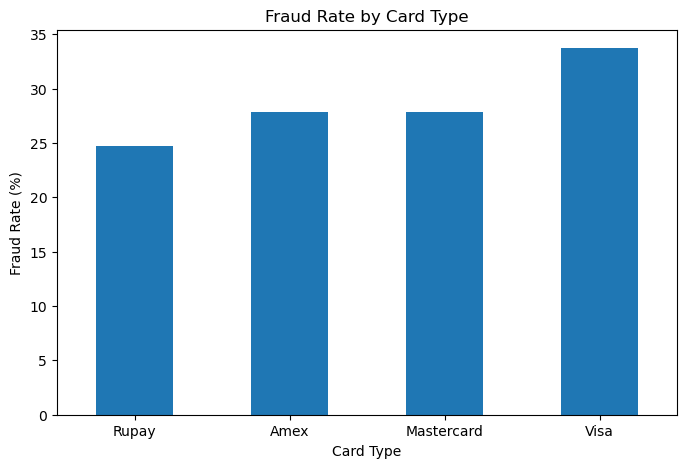

In [76]:
card_type_rate[1].sort_values().plot(
    kind='bar',
    figsize=(8,5)
)

plt.title('Fraud Rate by Card Type')
plt.xlabel('Card Type')
plt.ylabel('Fraud Rate (%)')
plt.xticks(rotation=0)
plt.show()

In [78]:
df.columns

Index(['Transaction ID', 'Customer Name', 'Merchant Name', 'Transaction Date',
       'Transaction Amount (INR)', 'Fraud Risk', 'Fraud Type', 'State',
       'Card Type', 'Bank', 'IsFraud', 'Fraud Score', 'Transaction Category',
       'Merchant Location', 'Transaction Month', 'Transaction Day'],
      dtype='object')

In [80]:
bank_fraud_rate=(pd.crosstab(df['Bank'],df['IsFraud'],normalize='index')*100).round(2)
bank_fraud_rate

IsFraud,0,1
Bank,,
Andhra Bank,65.25,34.75
Axis Bank,72.38,27.62
Bank of Baroda,73.58,26.42
Federal Bank,73.58,26.42
HDFC Bank,68.27,31.73
ICICI Bank,71.43,28.57
Kotak Bank,70.91,29.09
SBI,72.82,27.18
Yes Bank,74.59,25.41


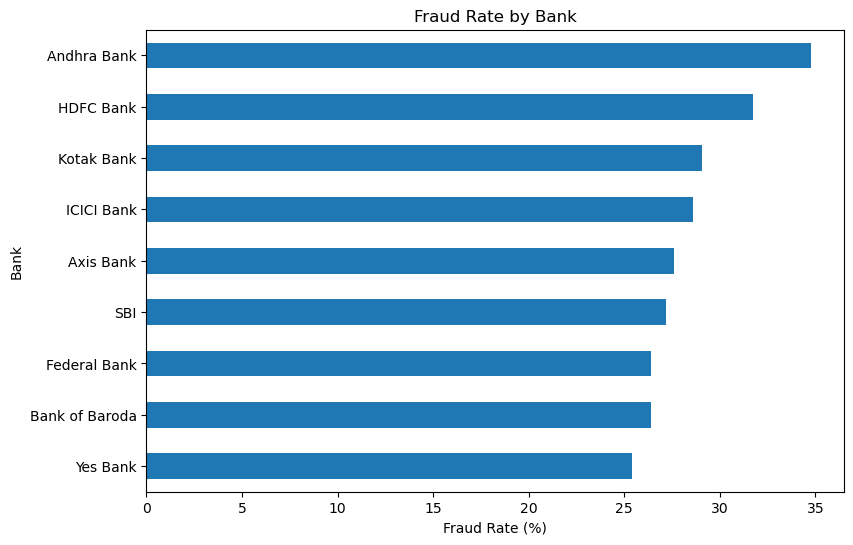

In [82]:
bank_fraud_rate[1].sort_values().plot(
    kind='barh',
    figsize=(9, 6)
)

plt.title('Fraud Rate by Bank')
plt.xlabel('Fraud Rate (%)')
plt.ylabel('Bank')
plt.show()

In [84]:
df.columns

Index(['Transaction ID', 'Customer Name', 'Merchant Name', 'Transaction Date',
       'Transaction Amount (INR)', 'Fraud Risk', 'Fraud Type', 'State',
       'Card Type', 'Bank', 'IsFraud', 'Fraud Score', 'Transaction Category',
       'Merchant Location', 'Transaction Month', 'Transaction Day'],
      dtype='object')

In [86]:
transaction_category_rate=(pd.crosstab(df['Transaction Category'],df['IsFraud'],normalize='index')*100).round(2)
transaction_category_rate

IsFraud,0,1
Transaction Category,,
Apparel,72.84,27.16
E-commerce,68.97,31.03
Electronics,69.83,30.17
Food Delivery,67.57,32.43
Groceries,73.38,26.62
Transportation,75.41,24.59


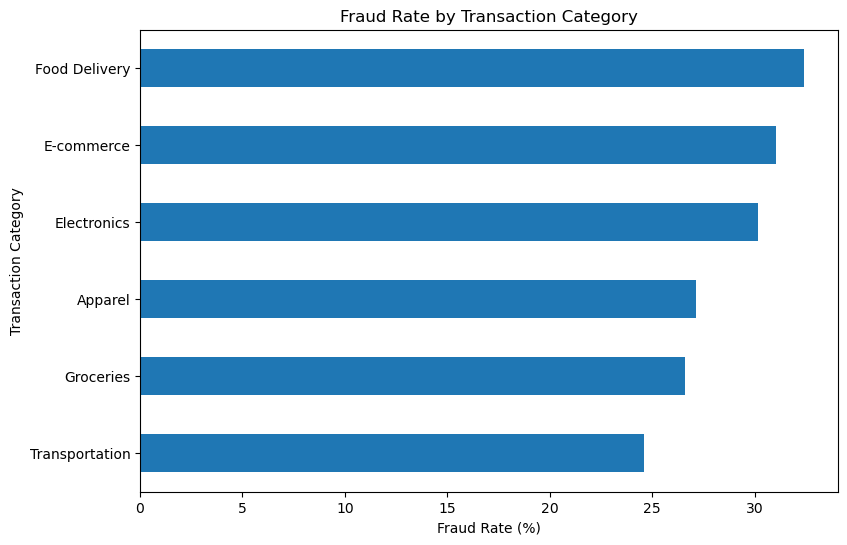

In [88]:
transaction_category_rate[1].sort_values().plot(
    kind='barh',
    figsize=(9, 6)
)

plt.title('Fraud Rate by Transaction Category')
plt.xlabel('Fraud Rate (%)')
plt.ylabel('Transaction Category')
plt.show()

In [90]:
fraud_score_analysis = (
    df.groupby('IsFraud')['Fraud Score']
    .agg(['count', 'mean', 'median', 'min', 'max'])
).round(2)

fraud_score_analysis

,count,mean,median,min,max
IsFraud,,,,,
0,714,52.88,54.0,10,95
1,286,53.93,55.0,10,95


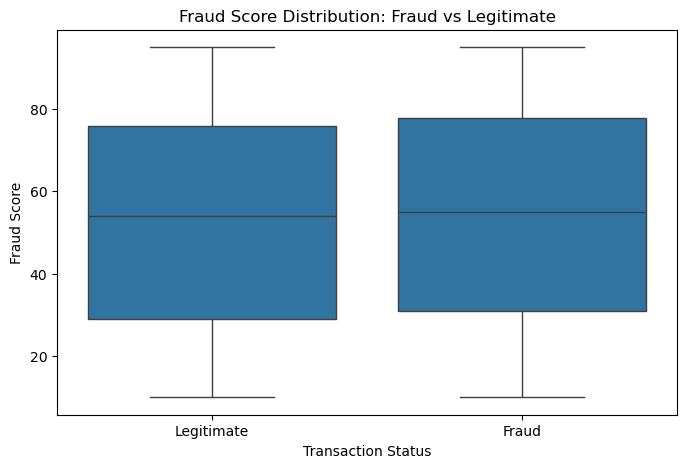

In [92]:
plt.figure(figsize=(8,5))

sns.boxplot(
    data=df,
    x='IsFraud',
    y='Fraud Score'
)

plt.title('Fraud Score Distribution: Fraud vs Legitimate')
plt.xlabel('Transaction Status')
plt.ylabel('Fraud Score')
plt.xticks([0, 1], ['Legitimate', 'Fraud'])

plt.show()

In [94]:
combined_analysis = (
    pd.crosstab(
        [df['Fraud Type'], df['Card Type']],
        df['IsFraud'],
        normalize='index'
    ) * 100
).round(2)

combined_analysis

IsFraud                          0      1
Fraud Type       Card Type               
Account Takeover Amex        66.67  33.33
                 Mastercard  85.00  15.00
                 Rupay       89.19  10.81
                 Visa        68.42  31.58
Card Not Present Amex        75.93  24.07
                 Mastercard  68.75  31.25
                 Rupay       68.75  31.25
                 Visa        63.08  36.92
Card Skimming    Amex        75.00  25.00
                 Mastercard  75.00  25.00
                 Rupay       74.00  26.00
                 Visa        72.55  27.45
Identity Theft   Amex        63.27  36.73
                 Mastercard  69.09  30.91
                 Rupay       72.73  27.27
                 Visa        63.83  36.17
Phishing         Amex        80.00  20.00
                 Mastercard  61.76  38.24
                 Rupay       76.92  23.08
                 Visa        63.41  36.59

In [96]:
combo_counts = (
    df.groupby(['Fraud Type', 'Card Type'])['IsFraud']
    .agg(['count', 'sum'])
    .rename(columns={'sum': 'Fraud Count'})
    .sort_values('count', ascending=False)
)

combo_counts

count  Fraud Count
Fraud Type       Card Type                     
Card Not Present Visa           65           24
                 Rupay          64           20
Card Skimming    Mastercard     60           15
Account Takeover Visa           57           18
Identity Theft   Mastercard     55           17
Account Takeover Amex           54           18
Card Not Present Amex           54           13
Phishing         Rupay          52           12
Card Skimming    Visa           51           14
Phishing         Amex           50           10
Card Skimming    Rupay          50           13
Identity Theft   Amex           49           18
Card Skimming    Amex           48           12
Card Not Present Mastercard     48           15
Identity Theft   Visa           47           17
                 Rupay          44           12
Phishing         Visa           41           15
Account Takeover Mastercard     40            6
                 Rupay          37            4
Phishing         Mastercard     34           13

In [98]:
overall_fraud_rate = df['IsFraud'].mean() * 100

print(f"Overall Fraud Rate: {overall_fraud_rate:.2f}%")

Overall Fraud Rate: 28.60%


In [100]:
df['Risk Signal Count'] = 0

# Fraud Type signal
df['Risk Signal Count'] += df['Fraud Type'].isin(
    ['Identity Theft', 'Card Not Present']
).astype(int)

# Card Type signal
df['Risk Signal Count'] += (
    df['Card Type'] == 'Visa'
).astype(int)

# State signal
df['Risk Signal Count'] += df['State'].isin(
    ['Karnataka', 'Maharashtra']
).astype(int)

# Bank signal
df['Risk Signal Count'] += df['Bank'].isin(
    ['Andhra Bank', 'HDFC Bank']
).astype(int)

# Merchant Location signal
top_locations = merchent_location_rate[1].nlargest(2).index

df['Risk Signal Count'] += df['Merchant Location'].isin(
    top_locations
).astype(int)

In [102]:
risk_signal_analysis = (
    df.groupby('Risk Signal Count')['IsFraud']
    .agg(['count', 'sum', 'mean'])
    .rename(columns={
        'sum': 'Fraud Count',
        'mean': 'Fraud Rate'
    })
)

risk_signal_analysis['Fraud Rate'] = (
    risk_signal_analysis['Fraud Rate'] * 100
).round(2)

risk_signal_analysis

,count,Fraud Count,Fraud Rate
Risk Signal Count,,,
0,213,38,17.84
1,396,107,27.02
2,280,96,34.29
3,93,40,43.01
4,17,5,29.41
5,1,0,0.00


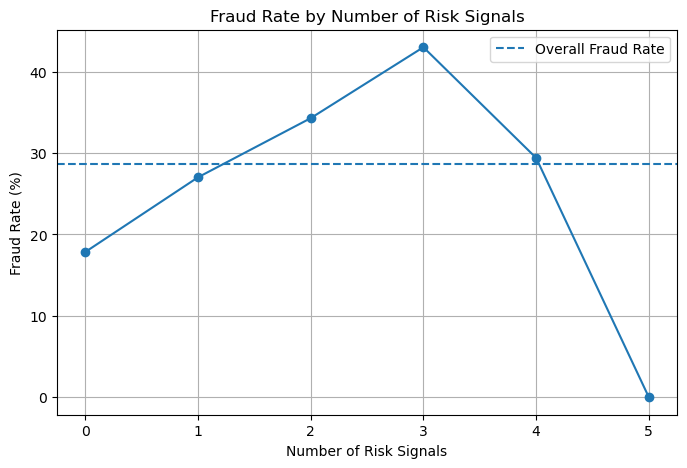

In [104]:
plt.figure(figsize=(8,5))

plt.plot(
    risk_signal_analysis.index,
    risk_signal_analysis['Fraud Rate'],
    marker='o'
)

plt.axhline(
    overall_fraud_rate,
    linestyle='--',
    label='Overall Fraud Rate'
)

plt.title('Fraud Rate by Number of Risk Signals')
plt.xlabel('Number of Risk Signals')
plt.ylabel('Fraud Rate (%)')
plt.legend()
plt.grid(True)

plt.show()

In [106]:
df.groupby('Risk Signal Count')['IsFraud'].agg(
    ['count', 'sum']
)

,count,sum
Risk Signal Count,,
0,213,38
1,396,107
2,280,96
3,93,40
4,17,5
5,1,0


In [108]:
df.columns

Index(['Transaction ID', 'Customer Name', 'Merchant Name', 'Transaction Date',
       'Transaction Amount (INR)', 'Fraud Risk', 'Fraud Type', 'State',
       'Card Type', 'Bank', 'IsFraud', 'Fraud Score', 'Transaction Category',
       'Merchant Location', 'Transaction Month', 'Transaction Day',
       'Risk Signal Count'],
      dtype='object')

In [110]:
df.columns

Index(['Transaction ID', 'Customer Name', 'Merchant Name', 'Transaction Date',
       'Transaction Amount (INR)', 'Fraud Risk', 'Fraud Type', 'State',
       'Card Type', 'Bank', 'IsFraud', 'Fraud Score', 'Transaction Category',
       'Merchant Location', 'Transaction Month', 'Transaction Day',
       'Risk Signal Count'],
      dtype='object')

In [112]:
df.to_csv('credit_card_fraud_analysis_cleaned.csv', index=False)